In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 11 - Wages and gender equality
Eurostat series on pay, working patterns, and gender gaps. Note: Italy has **no statutory national minimum wage**, so the Eurostat minimum-wage table has no Italian value.

,year,Italy,median others,rank (1 = highest)
"Employment gap, men minus women (20-64)",2025,19.1,7.0,1/27
Women in part-time work (20-64),2025,27.7,14.8,7/27
"Involuntary part-time, women",2025,46.6,18.0,1/26
Women outside labour force for care (25-54),2025,1.4,NaN,4/19
Women among managers,2025,29.0,37.3,25/27
Gender pension gap (65+),2025,29.2,22.0,5/27


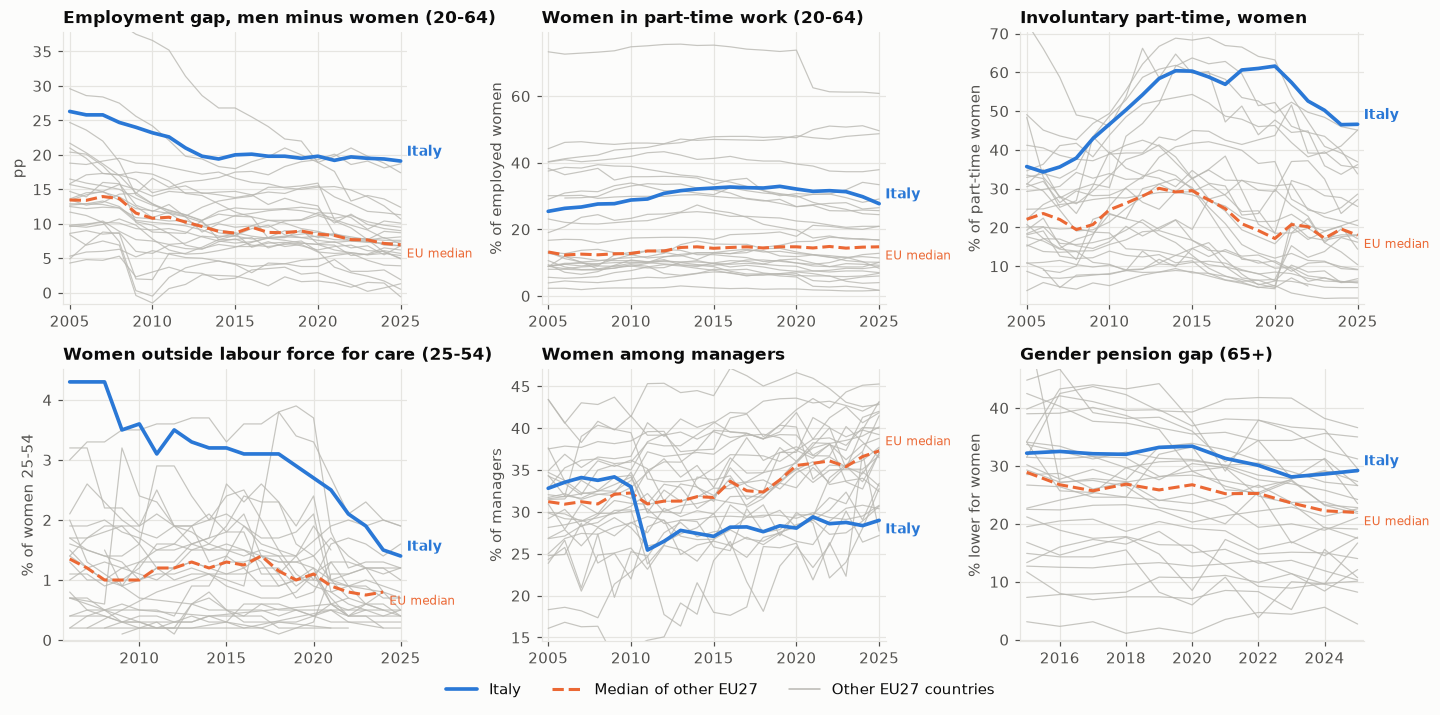

In [2]:
emp_gap = wide(panel, "employment_rate_20_64_male") - wide(panel, "employment_rate_20_64_female")
items = [
    (emp_gap, "Employment gap, men minus women (20-64)", "pp"),
    (wide(panel, "part_time_female_20_64"), "Women in part-time work (20-64)", "% of employed women"),
    (wide(panel, "involuntary_part_time_female_15_64"), "Involuntary part-time, women", "% of part-time women"),
    (wide(panel, "inactive_care_female_25_54"), "Women outside labour force for care (25-54)", "% of women 25-54"),
    (wide(panel, "women_managers_share_pct"), "Women among managers", "% of managers"),
    (wide(panel, "gender_pension_gap_65"), "Gender pension gap (65+)", "% lower for women"),
]
small_multiples_wide(items, ncols=3, name="11_gender_overview")
latest = {n: (w[ITALY].dropna().index.max(), round(w[ITALY].dropna().iloc[-1], 1), round(eu_median_ex_italy(w).loc[w[ITALY].dropna().index.max()], 1), "%d/%d" % italy_rank(w, w[ITALY].dropna().index.max())) for w, n, _ in items}
display(pd.DataFrame(latest, index=["year", "Italy", "median others", "rank (1 = highest)"]).T)

Overall earnings gap 2018 Italy: 43.0 | median of others: 27.7 | rank (3, 27)
corr(female employment, unadjusted pay gap) across EU27, 2022: 0.49


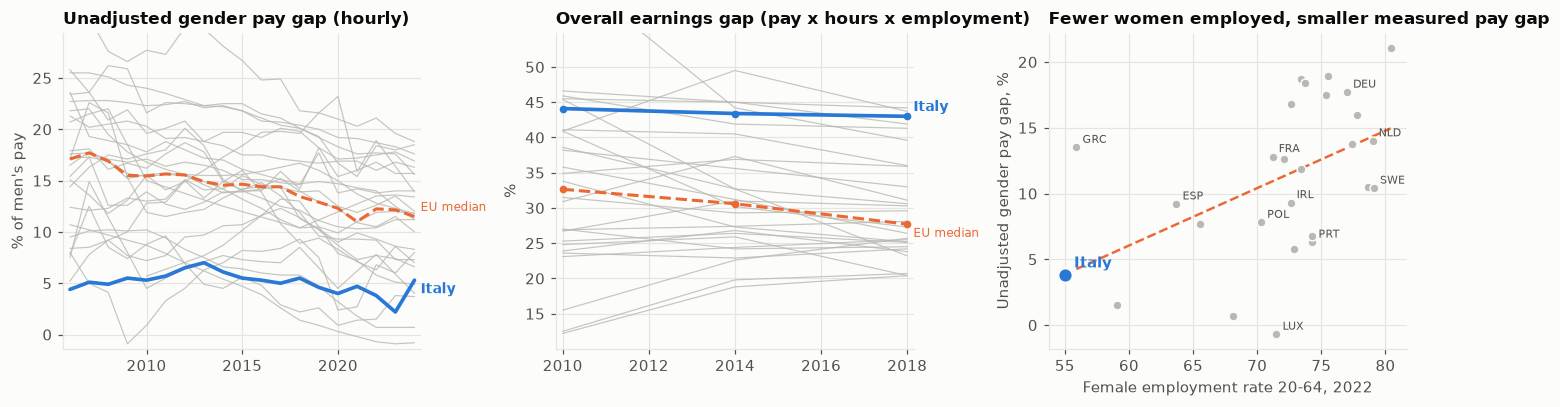

In [3]:
# Pay gaps: unadjusted vs overall. The unadjusted hourly gap is low where few women work (selection effect).
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
line_wide(axes[0], wide(panel, "gender_pay_gap"), "Unadjusted gender pay gap (hourly)", "% of men's pay")
line_wide(axes[1], wide(panel, "gender_overall_earnings_gap"), "Overall earnings gap (pay x hours x employment)", "%")
x = wide(panel, "employment_rate_20_64_female", EU27_ISO3).loc[2022]; y = wide(panel, "gender_pay_gap", EU27_ISO3).loc[2022]
scatter_italy(axes[2], x, y, "Female employment rate 20-64, 2022", "Unadjusted gender pay gap, %", "Fewer women employed, smaller measured pay gap")
fig.tight_layout(); save(fig, "11_pay_gaps")
w = wide(panel, "gender_overall_earnings_gap"); yl = w[ITALY].dropna().index.max()
print("Overall earnings gap", yl, "Italy:", round(w.loc[yl, ITALY], 1), "| median of others:", round(eu_median_ex_italy(w).loc[yl], 1), "| rank", italy_rank(w, yl))
print("corr(female employment, unadjusted pay gap) across EU27, 2022:", round(x.corr(y), 2))

gross Italy vs median of others: {2005: np.float64(106.0), 2010: np.float64(117.0), 2015: np.float64(124.0), 2019: np.float64(129.0), 2023: np.float64(120.0)} | vs Germany: {2005: np.float64(64.0), 2023: np.float64(63.0)} | new basis from 2024 (not comparable with 2023): {2024: (np.float64(110.0), np.float64(77.0)), 2025: (np.float64(108.0), np.float64(77.0))}
net Italy vs median of others: {2005: np.float64(95.0), 2010: np.float64(104.0), 2015: np.float64(112.0), 2019: np.float64(107.0), 2023: np.float64(114.0)} | vs Germany: {2005: np.float64(80.0), 2023: np.float64(72.0)} | new basis from 2024 (not comparable with 2023): {2024: (np.float64(106.0), np.float64(83.0)), 2025: (np.float64(105.0), np.float64(85.0))}


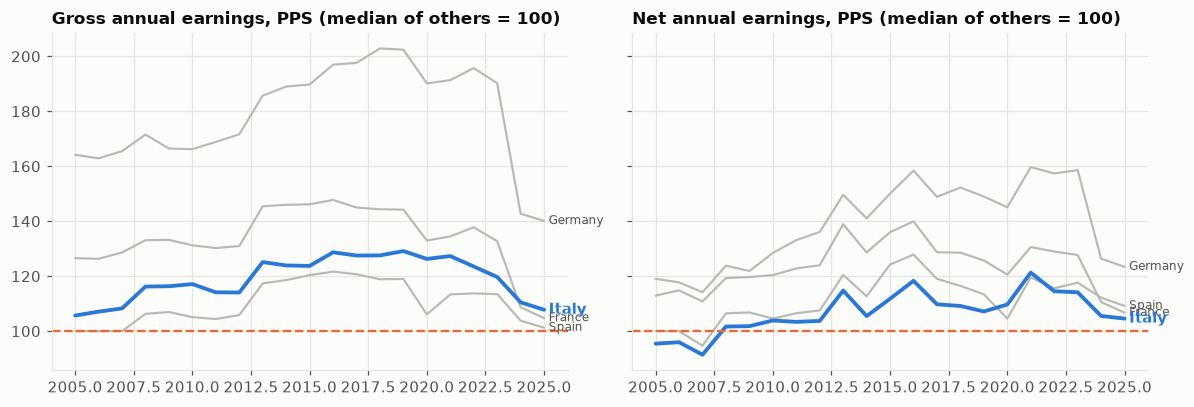

In [4]:
# Earnings level (average worker, single, no children, PPS): Italy relative to the median of the other members, and to DEU/FRA/ESP
net = wide(panel, "net_earnings_pps"); gross = wide(panel, "gross_earnings_pps")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, w, t in zip(axes, [gross, net], ["Gross annual earnings", "Net annual earnings"]):
    rel = w.div(eu_median_ex_italy(w), axis=0) * 100
    for c, lab in [("DEU", "Germany"), ("FRA", "France"), ("ESP", "Spain")]:
        d = rel[c].dropna(); ax.plot(d.index, d.values, color=PEER_C, lw=1.4); ax.annotate(lab, (d.index[-1], d.iloc[-1]), xytext=(3, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
    d = rel[ITALY].dropna(); ax.plot(d.index, d.values, color=ITALY_C, lw=2.5); ax.annotate("Italy", (d.index[-1], d.iloc[-1]), xytext=(3, 0), textcoords="offset points", color=ITALY_C, fontweight="bold", va="center")
    ax.axhline(100, color=EU_C, ls="--", lw=1.5); ax.set_title(f"{t}, PPS (median of others = 100)")
fig.tight_layout(); save(fig, "11_earnings_relative")
for lab, w in [("gross", gross), ("net", net)]:
    rel = (w[ITALY] / eu_median_ex_italy(w) * 100).dropna(); print(lab, "Italy vs median of others:", {y: round(rel.loc[y], 0) for y in (2005, 2010, 2015, 2019, 2023) if y in rel.index}, "| vs Germany:", {y: round(w.loc[y, ITALY] / w.loc[y, "DEU"] * 100, 0) for y in (2005, 2023)}, "| new basis from 2024 (not comparable with 2023):", {y: (round(rel.loc[y], 0), round(w.loc[y, ITALY] / w.loc[y, "DEU"] * 100, 0)) for y in (2024, 2025) if y in rel.index})

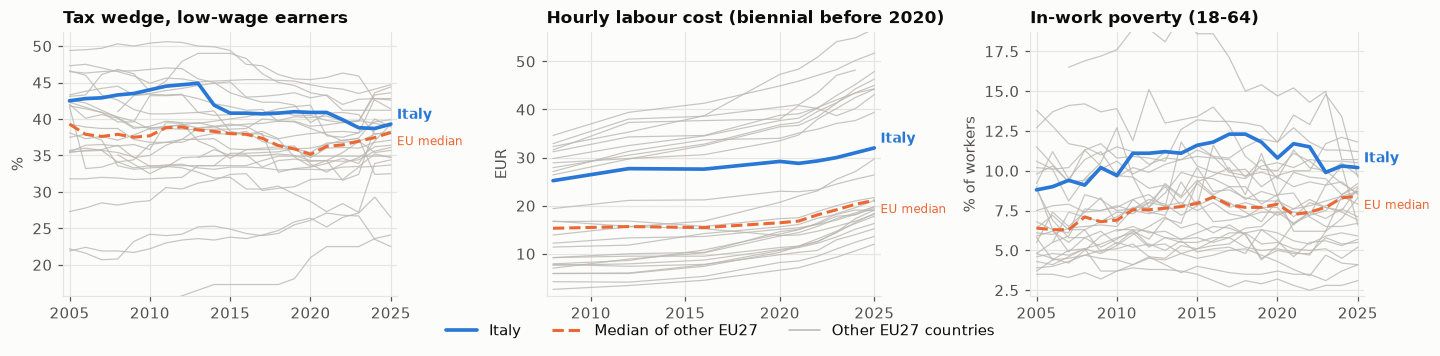

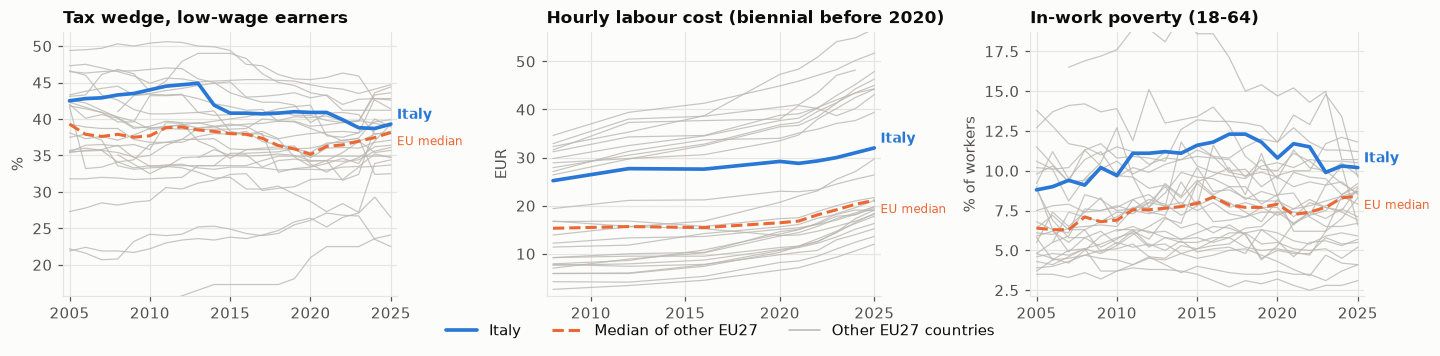

In [5]:
# Labour cost, tax wedge, in-work poverty
items = [
    (wide(panel, "tax_wedge_low_wage"), "Tax wedge, low-wage earners", "%"),
    (wide(panel, "labour_cost_hourly_eur"), "Hourly labour cost (biennial before 2020)", "EUR"),
    (wide(panel, "inwork_poverty_18_64"), "In-work poverty (18-64)", "% of workers"),
]
small_multiples_wide(items, ncols=3, name="11_wages_other")

In [6]:
# Figures quoted in the takeaways: Italy, median of the other members, rank (1 = highest) among the members with a value
def quoted(ind, years, countries=()):
    w = wide(panel, ind, EU27_ISO3)
    for y in years:
        r = w.loc[y].dropna()
        print(f"{ind} {y}: Italy {r[ITALY]:.2f} | median of the others {r.drop(ITALY).median():.2f} | rank {int(r.rank(ascending=False)[ITALY])}/{len(r)}" + "".join(f" | {c} {r[c]:.2f}" for c in countries))  # two decimals: a takeaway rounded to one is then checked without ties
gap = wide(panel, "employment_rate_20_64_male", EU27_ISO3) - wide(panel, "employment_rate_20_64_female", EU27_ISO3); print("employment gap, men minus women, Italy:", {y: round(float(gap.loc[y, ITALY]), 1) for y in (2005, 2025)})
quoted("inactive_care_female_25_54", [2006, 2025]); quoted("involuntary_part_time_male_15_64", [2025]); quoted("gender_pay_gap", [2023, 2024]); quoted("labour_cost_hourly_eur", [2024], ["DEU", "FRA"]); quoted("inwork_poverty_18_64", [2024, 2025]); quoted("tax_wedge_low_wage", [2023, 2024, 2025])

employment gap, men minus women, Italy: {2005: 26.3, 2025: 19.1}
inactive_care_female_25_54 2006: Italy 4.30 | median of the others 1.35 | rank 1/23
inactive_care_female_25_54 2025: Italy 1.40 | median of the others 0.70 | rank 4/19
involuntary_part_time_male_15_64 2025: Italy 65.90 | median of the others 21.20 | rank 2/24
gender_pay_gap 2023: Italy 2.20 | median of the others 12.15 | rank 25/27
gender_pay_gap 2024: Italy 5.30 | median of the others 11.50 | rank 22/27
labour_cost_hourly_eur 2024: Italy 31.00 | median of the others 20.30 | rank 11/27 | DEU 43.50 | FRA 43.40
inwork_poverty_18_64 2024: Italy 10.30 | median of the others 8.30 | rank 7/27
inwork_poverty_18_64 2025: Italy 10.20 | median of the others 8.40 | rank 5/27
tax_wedge_low_wage 2023: Italy 38.80 | median of the others 36.95 | rank 9/27
tax_wedge_low_wage 2024: Italy 38.70 | median of the others 37.45 | rank 11/27
tax_wedge_low_wage 2025: Italy 39.30 | median of the others 38.15 | rank 9/27


## Takeaways (Eurostat; 2025 values are provisional)
- **Employment is the core gender gap:** men's employment rate (20-64) exceeds women's by 19.1 pp against a 7.0 pp median, the largest in the EU27 (it was 26 pp in 2005). Italy's gap in women outside the labour force for care reasons (25-54) is 1.4% against 0.7% (4th of 19), down from 4.3% in 2006.
- **Women who work are often not working the hours they want:** 27.7% of employed women work part time (median 14.8%), and 46.6% of those part-timers want full-time work (median 18.0%; highest of 26 countries); for part-time men it is 65.9% (2nd of 24).
- **The unadjusted pay gap hides the problem.** Italy's hourly gap is about 5% (2024, provisional; 2.2% in 2023) against an 11.5% median, but the *overall* earnings gap, which combines pay, hours and employment, was 43.0% in 2018 (median 27.7%; 3rd highest; the latest year available). Across the EU27 the unadjusted gap is positively correlated with female employment (+0.49 in 2022): where fewer women work, the measured gap looks smaller.
- **Representation and pensions:** women are 29.0% of managers (median 37.3%; 25th of 27; there is a series break in 2011) and the gender pension gap is 29.2% (median 22.0%; 5th highest).
- **Pay levels:** for an average single worker, gross earnings in PPS were 120 and net earnings 114 (median of the other members = 100) in 2023, up from 106 and 95 in 2005 but down from the 2019 peak (129 and 107). Against Germany, gross pay was 64% in 2005 and 63% in 2023, net 80% then 72%. From 2024 Eurostat's average wage has a new basis (break flag; the Italian gross wage in euro is 13% above 2023, the German one 7% below), so the later values are a different measure, not a change: 110 and 106 in 2024, 108 and 105 in 2025 against the median, 77% gross and 83-85% net against Germany. Hourly labour cost was EUR 31.0 in 2024 vs 20.3 (median), 43.5 (Germany), 43.4 (France).
- **In-work poverty** is 10.2% vs 8.4% in 2025 (5th highest; 10.3% vs 8.3% and 7th in 2024); the tax wedge on low earners is 39.3% vs 38.1% in 2025 (9th; 38.7% vs 37.4% in 2024, the first year of the new basis of the earnings tables). Italy has no statutory national minimum wage (no value in the Eurostat table).